# Tutorial 5 — Exportação da malha de um aerofólio

## 1. Importações

In [1]:
from pathlib import Path
import sys

# Importar o pacote local
project_root = Path.cwd()
if project_root.name == "tutorials":
    project_root = project_root.parent
sys.path.insert(0, str(project_root))

import numpy as np

from meshlab.core import Mesh, Curve, Contour, Front
from meshlab.operations import (
    insert_contour, initialize_front, compute_normals, smooth_normals, advance_front,
)
from meshlab.utils import plot_mesh
from meshlab.export import export_mesh

## 2. Parâmetros

In [2]:
num_layers = 10
height = 0.005
growth_rate = 1.10
smooth_steps = 5
relaxation = 1.0
farfield_radius = 10.0
farfield_points = 80
thickness = 0.1
mesh_size = 0.5
show_gmsh = False             # True abre a janela interativa do Gmsh

filename = project_root / "tutorials/results/NACA-2412.msh"

## 3. Perfil NACA 2412

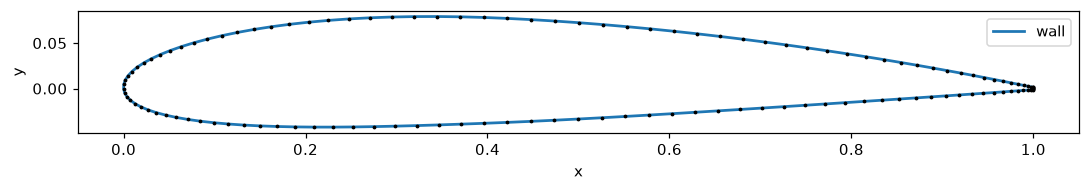

In [3]:
points = np.loadtxt(project_root / "tutorials/data/NACA-2412.dat")
# Fechar o percurso anti-horário do arquivo
points = np.vstack((points, points[0]))
surface = Contour("airfoil", [Curve("wall", points)])

mesh = Mesh(dim=2, vertices_capacity=5000, cells_capacity=5000)
insert_contour(mesh, surface)

front = Front("airfoil_front", int_dtype=mesh.int_dtype)
initialize_front(mesh, front, curves=["wall"])

plot_mesh(mesh);

## 4. Camadas próximas à parede

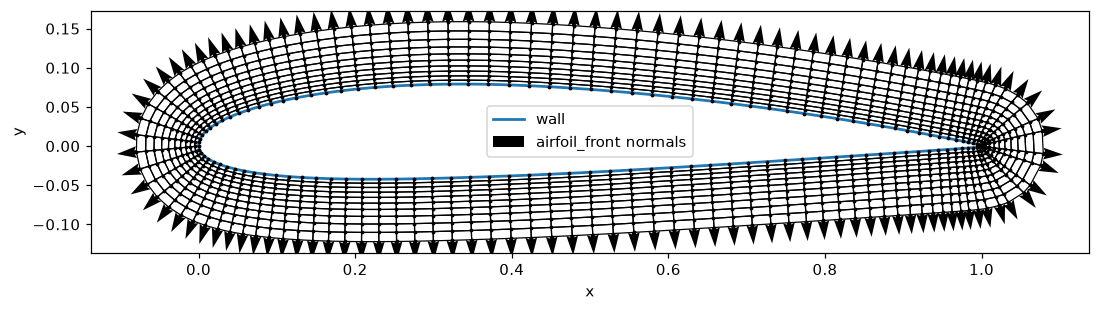

In [4]:
h = height
for _ in range(num_layers):
    normals = compute_normals(mesh, front, method="central")
    for _ in range(smooth_steps):
        normals, _ = smooth_normals(mesh, front, normals, relaxation)

    advance_front(mesh, front, normals, h)
    h *= growth_rate

# Recalcular as normais para os vértices atuais da frente
normals = compute_normals(mesh, front, method="central")
plot_mesh(mesh, normals=[(front, normals)], normal_scale=0.025);

## 5. Domínio externo

In [5]:
# Percurso horário do contorno externo
angles = np.linspace(0.0, -2.0 * np.pi, farfield_points, endpoint=False)
points = farfield_radius * np.column_stack((np.cos(angles), np.sin(angles)))
points = np.vstack((points, points[0]))

farfield = Contour("outer_domain", [Curve("freestream", points)])
insert_contour(mesh, farfield)

## 6. Preenchimento e exportação pelo Gmsh

In [6]:
filename.parent.mkdir(parents=True, exist_ok=True)

# Preservar as camadas, triangular a região residual e extrudar uma célula em z
export_mesh(
    mesh,
    fronts=[front],
    filename=filename,
    mode="planar",
    thickness=thickness,
    mesh_size=mesh_size,
    show=show_gmsh,
)

print(filename)

/home/user/Documentos/GitHub/meshlab/tutorials/results/NACA-2412.msh


## 7. Conversão para OpenFOAM

In [7]:
# Executar no terminal, dentro de um caso OpenFOAM preparado:
# gmshToFoam /caminho/para/tutorials/results/NACA-2412.msh
# Definir frontAndBack como empty em constant/polyMesh/boundary e nos campos.
# checkMesh -allTopology -allGeometry